# Comparación de los modelos de 2M sobre el conjunto de test

Evaluación final, **una sola vez**, sobre el split de **test** (shards 385-392: 40.687 imágenes, 10.172 panoramas).
Ningún modelo lo vio: no se usó para entrenar, ni para el early stopping, ni para elegir checkpoints. Todas las
decisiones se tomaron con val.

**Modelos** (todos ResNet-18, mismo split, mismo muestreo balanceado por rondas de 200k):

| Modelo | Clases | Receta |
|---|---|---|
| Celdas CE | 70 celdas (K-means) | CE simple, sin augmentation |
| Celdas CE + aug | 70 celdas | CE simple + RandomResizedCrop/ColorJitter |
| Celdas completo | 70 celdas | focal haversine + augmentation + SAM + snapshots (se usa el último snapshot corto) |
| Países 101 | 101 países | CE simple; cada país se ubica en su medoide para medir km |

**Cómo se generaron los logits:** `scripts/inferir_test.py`. Cada imagen pasa por la misma recompresión que train
y val en Colab (384 px, JPEG 90) y por la transformación de validación (Resize 224 + CenterCrop). Si falta algún
`__test.npy`, correr antes:

```
.venv/Scripts/python.exe scripts/inferir_test.py
```

**Dos modos de evaluación:**
- **1 vista:** cada imagen por separado. Unidad = imagen (40.687).
- **4 vistas:** se promedian los logits de las 4 vistas del panorama. Unidad = panorama (10.172).

**Qué se compara:**
1. Métricas en la tarea propia de cada modelo: top-1/3/5, balanced accuracy, F1 macro y ponderado, log loss, ECE.
2. **Métricas de país para todos:** permiten comparar celdas contra países. Un modelo de celdas reparte la
   probabilidad de cada celda entre países según la composición de esa celda en train.
3. Errores en distancia: mediana, media, percentiles, % por umbral y puntaje GeoGuessr (5000·e^(−km/1492.7)).
4. Matrices de confusión (celdas, países, continentes), pares más confundidos y mapas por país.
5. Diferencias contra la referencia (Celdas CE) con IC 95% por bootstrap pareado sobre panoramas.

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.colors import LinearSegmentedColormap, LogNorm

RAIZ = Path.cwd()
while not (RAIZ / "src" / "entrenamiento").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.entrenamiento.config import Config
from src.entrenamiento.entrenamiento import clases_y_tablas, haversine_np, resolver, softmax_np

BASE = RAIZ / "outputs" / "entrenamiento_2m"
REFERENCIA = "baseline_celdas_2m"
N_BOOTSTRAP = 1000
UMBRALES_KM = [25, 200, 750, 2500]
MODOS = ["1 vista", "4 vistas"]

# Nombre corto y color fijo por modelo (el color sigue al modelo en todos los gráficos).
NOMBRES = {"baseline_celdas_2m": "Celdas CE", "baseline_celdas_aug_2m": "Celdas CE + aug",
           "completo_2m": "Celdas completo", "baseline_paises101_2m": "Países 101",
           "baseline_paises_2m": "Países 71"}
COLORES = {"baseline_celdas_2m": "#2a78d6", "baseline_celdas_aug_2m": "#eb6834", "completo_2m": "#1baf7a",
           "baseline_paises101_2m": "#eda100", "baseline_paises_2m": "#e87ba4"}
SECUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f4f7fb", "#9ec3ef", "#2a78d6", "#0d3a73"])
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#c2410c", "#f2b48f", "#d9d9d6", "#9ec3ef", "#1d5fb0"])

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8986", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "font.size": 9, "legend.frameon": False})
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

## 1. Datos de test y modelos

In [2]:
test = pd.read_parquet(BASE / "test_filas.parquet")
# Panorama de cada imagen y una fila representativa por panorama (las 4 vistas comparten ubicación y país).
_, pano = np.unique(test["panoid"].to_numpy(), return_inverse=True)
n_pano = pano.max() + 1
primera = np.full(n_pano, -1)
primera[pano[::-1]] = np.arange(len(test))[::-1]
print(f"test: {len(test)} imágenes, {n_pano} panoramas, {test.country_code.nunique()} países, "
      f"{test.ind_cluster.nunique()} celdas")

# Universo de países (train + test) y P(país | celda) en train.
splits = pq.read_table(resolver("datasets/manifest_2m/splits.parquet"),
                       columns=["split", "ind_cluster", "country_code"]).to_pandas()
tr = splits[splits.split == "train"]
pais_tr = tr["country_code"].astype(str).str.strip().str.upper().to_numpy()
PAISES = sorted(set(pais_tr) | set(test.country_code))
IP = {p: i for i, p in enumerate(PAISES)}
conteo_celda_pais = np.zeros((tr["ind_cluster"].max() + 1, len(PAISES)))
np.add.at(conteo_celda_pais, (tr["ind_cluster"].to_numpy(), [IP[p] for p in pais_tr]), 1)
imagenes_train_celda = conteo_celda_pais.sum(1)
P_PAIS_CELDA = conteo_celda_pais / imagenes_train_celda[:, None]
pais_test = np.array([IP[p] for p in test.country_code])

# Continente de cada país (Natural Earth; los 3 que faltan en el mapa, a mano).
MUNDO = gpd.read_file(resolver("src/notebooks/eda/assets/ne_110m_admin_0_countries.geojson"))
# Territorios chicos que no están en el mapa de 110m.
CONTINENTE = dict(zip(MUNDO.ISO_A2_EH, MUNDO.CONTINENT)) | {
    "HK": "Asia", "SG": "Asia", "IM": "Europe", "AD": "Europe", "AX": "Europe", "FO": "Europe", "JE": "Europe",
    "LI": "Europe", "MT": "Europe", "SM": "Europe", "BM": "North America", "CW": "North America",
    "VI": "North America", "RE": "Africa", "ST": "Africa"}
CONTINENTES = ["North America", "South America", "Europe", "Africa", "Asia", "Oceania"]
cont_de_pais = np.array([CONTINENTES.index(CONTINENTE[p]) if CONTINENTE.get(p) in CONTINENTES else -1
                         for p in PAISES])
sin_continente = [p for p, k in zip(PAISES, cont_de_pais) if k < 0]
print("países sin continente en el mapa:", sin_continente)

corridas = sorted(p.parent.parent.name for p in BASE.glob("*/logits/*__test.npy") if p.parent.parent.name in NOMBRES)
print("corridas con logits de test:", [NOMBRES[n] for n in corridas])

test: 40687 imágenes, 10172 panoramas, 92 países, 68 celdas
países sin continente en el mapa: []
corridas con logits de test: ['Celdas CE', 'Celdas CE + aug', 'Países 101', 'Celdas completo']


In [3]:
def cargar_cfg(carpeta: Path) -> Config:
    datos = json.loads((carpeta / "config.json").read_text(encoding="utf-8"))
    datos.pop("huella", None)
    for campo in ("manifest", "splits", "val_global"):  # Rutas de Colab -> locales por defecto.
        if datos.get(campo) and not resolver(datos[campo]).exists():
            datos.pop(campo)
    return Config(**datos)


modelos = {}
for nombre in corridas:
    carpeta = BASE / nombre
    cfg = cargar_cfg(carpeta)
    if cfg.tarea == "celdas":
        proto_df = pd.read_csv(resolver(cfg.prototipos)).sort_values("ind_cluster")
        proto, clases = proto_df[["lat", "lon"]].to_numpy(np.float64), [str(c) for c in proto_df.ind_cluster]
        y = test["ind_cluster"].to_numpy()
        a_pais = P_PAIS_CELDA
    else:  # Medoides calculados igual que en el entrenamiento (sobre train, misma semilla).
        proto, _, clases = clases_y_tablas(cfg)
        indice = {p: i for i, p in enumerate(clases)}
        y = test["country_code"].map(indice).fillna(-1).astype(int).to_numpy()
        a_pais = np.zeros((len(clases), len(PAISES)))
        a_pais[np.arange(len(clases)), [IP[p] for p in clases]] = 1
    logits = np.load(next((carpeta / "logits").glob("*__test.npy"))).astype(np.float64)
    assert logits.shape == (len(test), len(clases)), (nombre, logits.shape)
    modelos[nombre] = {"tarea": cfg.tarea, "clases": clases, "proto": proto, "y": y, "a_pais": a_pais,
                       "logits": logits}
    fuera = (y < 0).mean()
    print(f"{NOMBRES[nombre]:16s} {cfg.tarea:7s} {len(clases):3d} clases | imágenes de test fuera de sus clases: "
          f"{fuera:.2%}")

Celdas CE        celdas   70 clases | imágenes de test fuera de sus clases: 0.00%
Celdas CE + aug  celdas   70 clases | imágenes de test fuera de sus clases: 0.00%
Países 101       paises  101 clases | imágenes de test fuera de sus clases: 0.00%
Celdas completo  celdas   70 clases | imágenes de test fuera de sus clases: 0.00%


## 2. Predicciones por modo

Para cada modelo y modo se calcula: probabilidades, clase predicha, distancia a la ubicación real, distribución
sobre países y la distancia del **oráculo**. El oráculo es la mejor distancia posible eligiendo la clase ideal:
el prototipo o medoide más cercano a la foto. Es el piso de error que impone discretizar en esas clases.

In [4]:
lat, lon = test["latitude"].to_numpy(), test["longitude"].to_numpy()
pred = {}
for nombre, m in modelos.items():
    dist_proto = haversine_np(lat[:, None], lon[:, None], m["proto"][None, :, 0], m["proto"][None, :, 1])
    for modo in MODOS:
        if modo == "1 vista":
            lg, filas, grupo = m["logits"], np.arange(len(test)), pano
        else:
            suma = np.zeros((n_pano, m["logits"].shape[1]))
            np.add.at(suma, pano, m["logits"])
            lg, filas, grupo = suma / np.bincount(pano)[:, None], primera, np.arange(n_pano)
        p = softmax_np(lg)
        k = p.argmax(1)
        d = dist_proto[filas]
        km = d[np.arange(len(filas)), k]
        pp = p @ m["a_pais"]
        pred[(nombre, modo)] = {"p": p, "pred": k, "y": m["y"][filas], "km": km, "km_oraculo": d.min(1),
                                "p_pais": pp, "pred_pais": pp.argmax(1), "y_pais": pais_test[filas],
                                "puntaje": 5000 * np.exp(-km / 1492.7), "grupo": grupo}

## 3. Métricas en la tarea propia

Top-k, balanced accuracy (recall medio por clase) y F1 sobre las clases de cada modelo. En **Países 101**, las
imágenes de países que no están entre sus 101 cuentan como error en top-k y como falsos positivos de la clase
predicha. Quedan afuera del recall medio porque no tienen una clase propia.

Ojo: celdas y países no son comparables entre sí en esta tabla, porque son tareas distintas (70 contra 101
clases, de tamaños muy distintos). Para comparar entre modelos están las secciones 4 y 5.

In [5]:
def top_k(p, y, k):
    mejores = np.argpartition(-p, k - 1, axis=1)[:, :k]
    return float((mejores == y[:, None]).any(1).mean())


def por_clase(y, pred, num_clases):
    """Precisión, recall, F1 y soporte por clase. Filas con y = -1: no suman soporte, sí cuentan como predicción."""
    v = y >= 0
    cm = np.zeros((num_clases, num_clases))
    np.add.at(cm, (y[v], pred[v]), 1)
    tp, soporte = np.diag(cm), cm.sum(1)
    predichos = np.bincount(pred, minlength=num_clases)
    prec = np.divide(tp, predichos, out=np.zeros_like(tp), where=predichos > 0)
    rec = np.divide(tp, soporte, out=np.zeros_like(tp), where=soporte > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return pd.DataFrame({"precision": prec, "recall": rec, "f1": f1, "soporte": soporte}), cm


def resumen_clases(y, pred, num_clases):
    pc, cm = por_clase(y, pred, num_clases)
    pres = pc[pc.soporte > 0]
    return {"bal_acc": pres.recall.mean(), "f1_macro": pres.f1.mean(),
            "f1_ponderado": (pres.f1 * pres.soporte).sum() / pres.soporte.sum(),
            "precision_macro": pres.precision.mean(), "recall_macro": pres.recall.mean()}, pc, cm


def ece(p, acierto, bins=15):
    conf = p.max(1)
    b = np.clip((conf * bins).astype(int), 0, bins - 1)
    return float(sum((b == i).mean() * abs(acierto[b == i].mean() - conf[b == i].mean())
                     for i in range(bins) if (b == i).any()))


filas_tarea, por_clase_tarea, cm_tarea = [], {}, {}
for (nombre, modo), r in pred.items():
    y, p = r["y"], r["p"]
    v = y >= 0
    res, pc, cm = resumen_clases(y, r["pred"], p.shape[1])
    por_clase_tarea[(nombre, modo)], cm_tarea[(nombre, modo)] = pc, cm
    filas_tarea.append({"modelo": NOMBRES[nombre], "modo": modo, "clases": p.shape[1],
                        "top1": top_k(p, y, 1), "top3": top_k(p, y, 3), "top5": top_k(p, y, 5), **res,
                        "log_loss": float(-np.log(np.clip(p[v, y[v]], 1e-12, None)).mean()),
                        "ece": ece(p, r["pred"] == y)})
tabla_tarea = pd.DataFrame(filas_tarea).sort_values(["modo", "modelo"]).set_index(["modo", "modelo"])
tabla_tarea.style.format("{:.3f}").format("{:.0f}", subset=["clases"]).background_gradient(
    cmap=SECUENCIAL, axis=0, subset=["top1", "top3", "top5", "bal_acc", "f1_macro"])

## 4. Métricas de país (comparables entre todos los modelos)

País predicho = argmax de la probabilidad sumada por país. Se calcula sobre los 118 países del dataset, y las
imágenes de cualquier país cuentan. Para Países 101, un país fuera de su lista es siempre un error.
Se agregan también las métricas por **continente**.

**Cómo leer `bal_acc` y `f1_macro` de país:** promedian por igual los 92 países que aparecen en test, también los
que tienen muy pocas imágenes. Un modelo de 70 celdas casi nunca predice un país chico: la celda donde cae ese
país es mayoritariamente de un país vecino más grande, y el argmax se queda con el grande. Por eso esas dos
métricas son mucho más bajas para los modelos de celdas, aunque su top-1 de país sea parecido. No es un error de
la cuenta: es una limitación real de discretizar en 70 celdas.

In [6]:
filas_pais, por_clase_pais, cm_pais, cm_cont = [], {}, {}, {}
for (nombre, modo), r in pred.items():
    pp, yp = r["p_pais"], r["y_pais"]
    res, pc, cm = resumen_clases(yp, r["pred_pais"], len(PAISES))
    por_clase_pais[(nombre, modo)], cm_pais[(nombre, modo)] = pc, cm
    p_cont = np.stack([pp[:, cont_de_pais == k].sum(1) for k in range(len(CONTINENTES))], 1)
    y_cont = cont_de_pais[yp]
    res_c, _, cm_c = resumen_clases(y_cont, p_cont.argmax(1), len(CONTINENTES))
    cm_cont[(nombre, modo)] = cm_c
    filas_pais.append({"modelo": NOMBRES[nombre], "modo": modo,
                       "top1": top_k(pp, yp, 1), "top3": top_k(pp, yp, 3), "top5": top_k(pp, yp, 5),
                       **res, "continente_top1": float((p_cont.argmax(1) == y_cont).mean()),
                       "continente_bal_acc": res_c["bal_acc"]})
tabla_pais = pd.DataFrame(filas_pais).sort_values(["modo", "modelo"]).set_index(["modo", "modelo"])
tabla_pais.style.format("{:.3f}").background_gradient(cmap=SECUENCIAL, axis=0)

## 5. Errores en distancia

- `km_oraculo_mediana`: el piso de error por discretizar.
- `puntaje`: el puntaje GeoGuessr medio por ronda, sobre 5000.
- `pct_Xkm`: la fracción de predicciones a menos de X km.

In [7]:
filas_km = []
for (nombre, modo), r in pred.items():
    km = r["km"]
    filas_km.append({"modelo": NOMBRES[nombre], "modo": modo, "km_mediana": np.median(km), "km_media": km.mean(),
                     "km_p25": np.percentile(km, 25), "km_p75": np.percentile(km, 75),
                     "km_p90": np.percentile(km, 90), "puntaje": r["puntaje"].mean(),
                     **{f"pct_{u}km": (km <= u).mean() for u in UMBRALES_KM},
                     "km_oraculo_mediana": np.median(r["km_oraculo"])})
tabla_km = pd.DataFrame(filas_km).sort_values(["modo", "modelo"]).set_index(["modo", "modelo"])
formato = {col: "{:.0f}" for col in tabla_km.columns if col.startswith("km") or col == "puntaje"}
formato |= {col: "{:.1%}" for col in tabla_km.columns if col.startswith("pct")}
tabla_km.style.format(formato).background_gradient(cmap=SECUENCIAL.reversed(), axis=0,
                                                    subset=["km_mediana", "km_media"]).background_gradient(
    cmap=SECUENCIAL, axis=0, subset=["puntaje"])

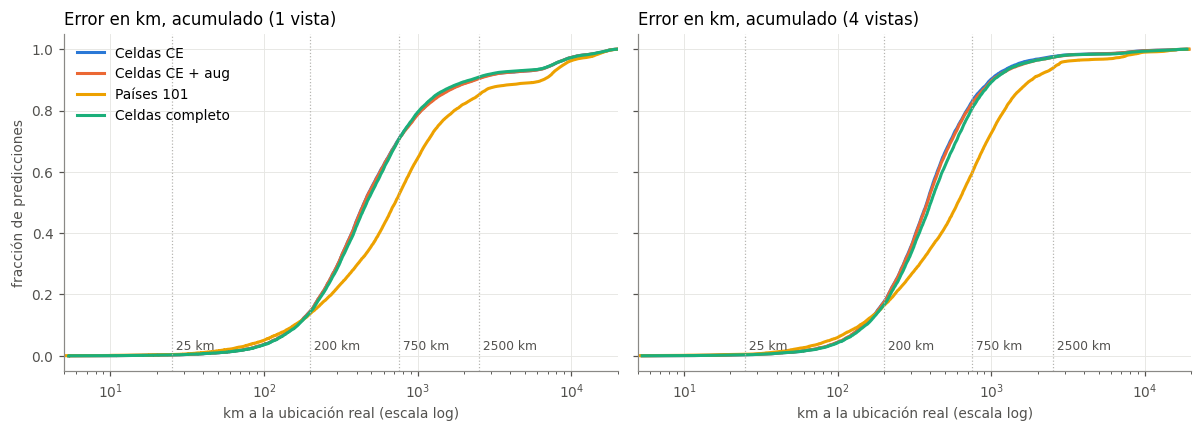

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, modo in zip(ejes, MODOS):
    for nombre in modelos:
        km = np.sort(pred[(nombre, modo)]["km"])
        eje.plot(km, np.arange(1, len(km) + 1) / len(km), color=COLORES[nombre], lw=2, label=NOMBRES[nombre])
    for u in [25, 200, 750, 2500]:
        eje.axvline(u, color="#b5b4b0", lw=0.8, ls=":")
        eje.text(u, 0.02, f" {u} km", color="#52514e", fontsize=8)
    eje.set_xscale("log")
    eje.set_xlim(5, 20000)
    eje.set_title(f"Error en km, acumulado ({modo})", loc="left")
    eje.set_xlabel("km a la ubicación real (escala log)")
ejes[0].set_ylabel("fracción de predicciones")
ejes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

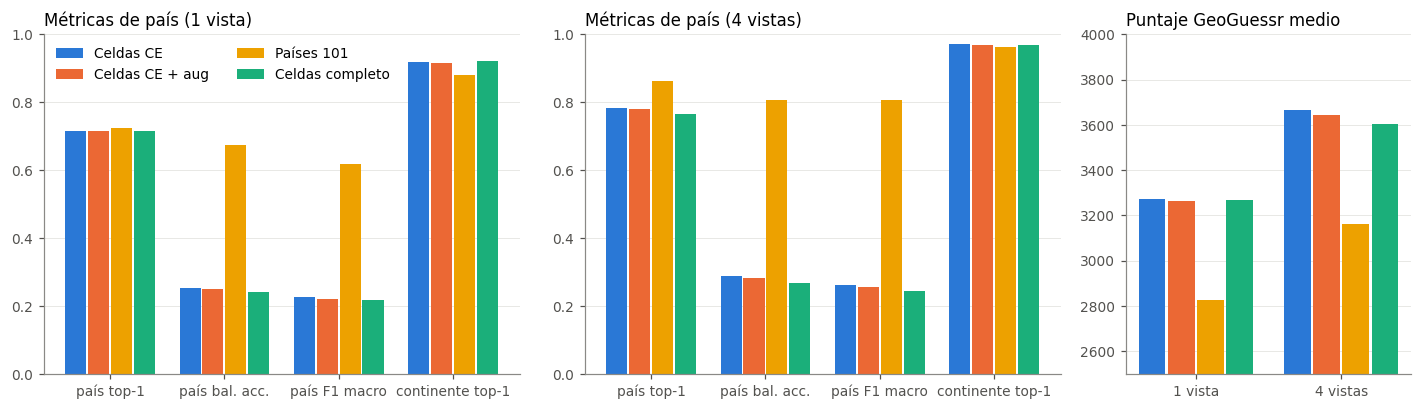

In [9]:
# Resumen visual de las métricas principales: país (comparables entre todos) y puntaje GeoGuessr.
metricas_barras = [("top1", "país top-1"), ("bal_acc", "país bal. acc."), ("f1_macro", "país F1 macro"),
                   ("continente_top1", "continente top-1")]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 2, 1.2]})
ancho = 0.8 / len(modelos)
for eje, modo in zip(ejes[:2], MODOS):
    for j, nombre in enumerate(modelos):
        vals = [tabla_pais.loc[(modo, NOMBRES[nombre]), m] for m, _ in metricas_barras]
        x = np.arange(len(metricas_barras)) + (j - (len(modelos) - 1) / 2) * ancho
        eje.bar(x, vals, width=ancho * 0.92, color=COLORES[nombre], label=NOMBRES[nombre])
    eje.set_xticks(np.arange(len(metricas_barras)), [t for _, t in metricas_barras])
    eje.set_ylim(0, 1)
    eje.set_title(f"Métricas de país ({modo})", loc="left")
    eje.grid(axis="x", visible=False)
ejes[0].legend(loc="upper left", ncol=2)
for j, nombre in enumerate(modelos):
    vals = [tabla_km.loc[(modo, NOMBRES[nombre]), "puntaje"] for modo in MODOS]
    x = np.arange(len(MODOS)) + (j - (len(modelos) - 1) / 2) * ancho
    ejes[2].bar(x, vals, width=ancho * 0.92, color=COLORES[nombre])
ejes[2].set_xticks(np.arange(len(MODOS)), MODOS)
ejes[2].set_ylim(2500, 4000)
ejes[2].set_title("Puntaje GeoGuessr medio", loc="left")
ejes[2].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 6. ¿Las diferencias son significativas? Bootstrap pareado contra la referencia

Se remuestrean panoramas con reposición, porque las 4 vistas de un panorama no son independientes. Se usa el
mismo remuestreo para los dos modelos que se comparan. La diferencia es *modelo − referencia*. Si el IC 95% no
contiene el 0, la diferencia es significativa.

In [10]:
rng = np.random.default_rng(0)
filas_boot = []
for modo in MODOS:
    ref = pred[(REFERENCIA, modo)]
    g = ref["grupo"]
    pesos = np.stack([np.bincount(rng.integers(0, n_pano, n_pano), minlength=n_pano)[g] for _ in range(N_BOOTSTRAP)])
    unidad = {n: {"país top-1": (pred[(n, modo)]["pred_pais"] == pred[(n, modo)]["y_pais"]).astype(float),
                  "continente top-1": (cont_de_pais[pred[(n, modo)]["pred_pais"]]
                                       == cont_de_pais[pred[(n, modo)]["y_pais"]]).astype(float),
                  "km media": pred[(n, modo)]["km"], "puntaje GeoGuessr": pred[(n, modo)]["puntaje"]}
              for n in modelos}
    for nombre in modelos:
        if nombre == REFERENCIA:
            continue
        for metrica, a in unidad[nombre].items():
            dif = a - unidad[REFERENCIA][metrica]
            dist = (pesos @ dif) / pesos.sum(1)
            lo, hi = np.percentile(dist, [2.5, 97.5])
            filas_boot.append({"modo": modo, "modelo": NOMBRES[nombre], "métrica": metrica, "diferencia": dif.mean(),
                               "IC95 inf": lo, "IC95 sup": hi, "significativa": "sí" if lo > 0 or hi < 0 else "no"})
tabla_boot = pd.DataFrame(filas_boot)
print(f"Referencia: {NOMBRES[REFERENCIA]}")
tabla_boot.pivot_table(index=["modo", "modelo"], columns="métrica",
                       values="diferencia").round(3).join(
    tabla_boot.assign(ic=lambda d: d.apply(lambda f: f"[{f['IC95 inf']:+.3g}, {f['IC95 sup']:+.3g}]", axis=1))
    .pivot_table(index=["modo", "modelo"], columns="métrica", values="ic", aggfunc="first"), rsuffix=" IC95")

Referencia: Celdas CE


métrica                   continente top-1  km media  país top-1  puntaje GeoGuessr  continente top-1 IC95   km media IC95        país top-1 IC95 puntaje GeoGuessr IC95
modo     modelo                                                                                                                                                         
1 vista  Celdas CE + aug            -0.004     7.460      -0.000             -6.701  [-0.00629, -0.000934]  [-18.5, +32.4]   [-0.00317, +0.00241]           [-17, +3.75]
         Celdas completo            -0.002   -12.322       0.000             -3.303  [-0.00479, +0.000541]  [-38.6, +12.9]    [-0.00322, +0.0032]         [-14.4, +7.44]
         Países 101                 -0.025   528.491       0.009           -445.608     [-0.0294, -0.0208]    [+491, +565]    [+0.00113, +0.0162]           [-468, -422]
4 vistas Celdas CE + aug            -0.003    17.958      -0.004            -19.539   [-0.00551, -0.00059]  [-2.09, +38.7]  [-0.00737, -9.59e-05]         [-31.1, -6.82]
         Celdas completo            -0.002    46.592      -0.017            -61.005   [-0.00462, +0.00138]  [+22.7, +70.3]     [-0.0227, -0.0129]         [-73.8, -47.3]
         Países 101                  0.001   405.814       0.081           -500.909    [-0.00344, +0.0056]    [+373, +438]     [+0.0722, +0.0898]           [-524, -476]

## 7. Matrices de confusión

### 7.1 Celdas (70 × 70)

Normalizadas por fila: la fila es la celda real y cada fila suma 1. Las celdas están ordenadas por continente
(según su país mayoritario en train) y, dentro de cada uno, por longitud. Así, las confusiones entre celdas
vecinas quedan cerca de la diagonal. La escala de color es logarítmica para que se vean los errores chicos.

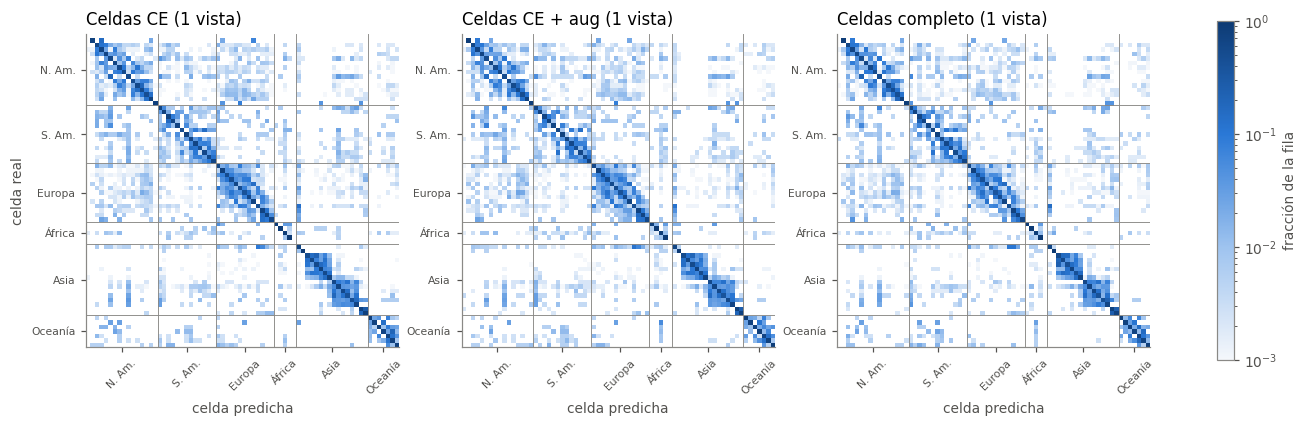

,continente (orden de los bloques),celdas
0,North America,16
1,South America,13
2,Europe,13
3,Africa,5
4,Asia,16
5,Oceania,7


In [11]:
celdas_modelos = [n for n in modelos if modelos[n]["tarea"] == "celdas"]
if celdas_modelos:
    proto_c = modelos[celdas_modelos[0]]["proto"]
    cont_celda = cont_de_pais[P_PAIS_CELDA.argmax(1)]
    orden = np.lexsort((proto_c[:, 1], cont_celda))
    cortes = np.flatnonzero(np.diff(cont_celda[orden])) + 0.5
    fig, ejes = plt.subplots(1, len(celdas_modelos), figsize=(5.2 * len(celdas_modelos), 5))
    ejes = np.atleast_1d(ejes)
    for eje, nombre in zip(ejes, celdas_modelos):
        cm = cm_tarea[(nombre, "1 vista")][np.ix_(orden, orden)]
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        im = eje.imshow(np.where(cmn > 0, cmn, np.nan), cmap=SECUENCIAL, norm=LogNorm(1e-3, 1))
        for x in cortes:
            eje.axhline(x, color="#8a8986", lw=0.6)
            eje.axvline(x, color="#8a8986", lw=0.6)
        eje.set_title(f"{NOMBRES[nombre]} (1 vista)", loc="left")
        eje.set_xlabel("celda predicha")
        eje.grid(False)
        bordes = np.concatenate([[-0.5], cortes, [len(orden) - 0.5]])
        centros = (bordes[:-1] + bordes[1:]) / 2
        nombres_bloques = ["N. Am.", "S. Am.", "Europa", "África", "Asia", "Oceanía"]
        etiquetas_b = [nombres_bloques[k] for k in np.unique(cont_celda[orden])]
        eje.set_xticks(centros, etiquetas_b, rotation=45, fontsize=7)
        eje.set_yticks(centros, etiquetas_b, fontsize=7)
    ejes[0].set_ylabel("celda real")
    fig.colorbar(im, ax=ejes, shrink=0.8, label="fracción de la fila")
    plt.show()
    display(pd.DataFrame({"continente (orden de los bloques)": [CONTINENTES[k] for k in np.unique(cont_celda[orden])],
                  "celdas": np.bincount(cont_celda)[np.unique(cont_celda)]}))

Errores entre celdas: ¿cuántos errores caen en una celda **vecina**? Se toman como vecinas las 3 celdas
con prototipo más cercano. Si la mayoría de los errores son entre vecinas, el modelo ubica bien la región y
falla en el corte fino.

In [12]:
if celdas_modelos:
    d_cc = haversine_np(proto_c[:, None, 0], proto_c[:, None, 1], proto_c[None, :, 0], proto_c[None, :, 1])
    np.fill_diagonal(d_cc, np.inf)
    vecinas = np.argsort(d_cc, axis=1)[:, :3]
    filas = []
    for nombre in celdas_modelos:
        for modo in MODOS:
            r = pred[(nombre, modo)]
            err = r["pred"] != r["y"]
            vec = (vecinas[r["y"][err]] == r["pred"][err][:, None]).any(1)
            filas.append({"modelo": NOMBRES[nombre], "modo": modo, "errores": err.mean(),
                          "errores entre vecinas (de los errores)": vec.mean(),
                          "km mediana de los errores": np.median(r["km"][err])})
    display(pd.DataFrame(filas).set_index(["modo", "modelo"]).style.format("{:.1%}").format(
        "{:.0f}", subset=["km mediana de los errores"]))

,,errores,errores entre vecinas (de los errores),km mediana de los errores
modo,modelo,,,
1 vista,Celdas CE,39.6%,55.9%,1039
4 vistas,Celdas CE,26.5%,72.7%,800
1 vista,Celdas CE + aug,40.0%,56.1%,1042
4 vistas,Celdas CE + aug,27.3%,71.8%,814
1 vista,Celdas completo,42.7%,60.4%,950
4 vistas,Celdas completo,32.6%,75.8%,775


F1 por celda contra la cantidad de imágenes de train de la celda. En val ya había aparecido que las celdas
densas rinden peor, por la confusión con vecinas.

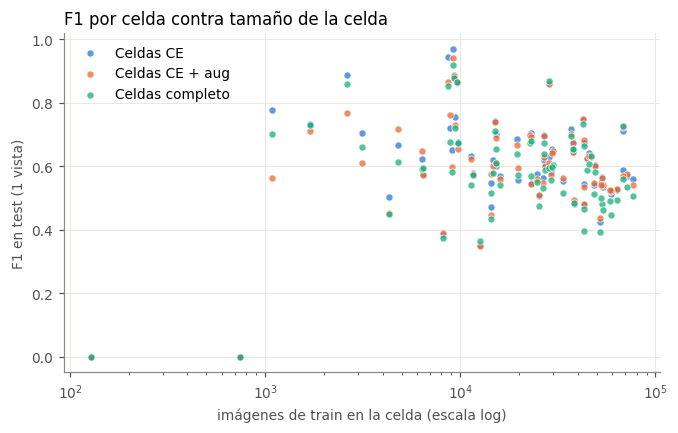

Correlación de Spearman F1 ~ tamaño: {'Celdas CE': np.float64(-0.267), 'Celdas CE + aug': np.float64(-0.207), 'Celdas completo': np.float64(-0.258)}


In [13]:
if celdas_modelos:
    fig, eje = plt.subplots(figsize=(7, 4))
    for nombre in celdas_modelos:
        pc = por_clase_tarea[(nombre, "1 vista")]
        eje.scatter(imagenes_train_celda, pc.f1, s=22, color=COLORES[nombre], alpha=0.75, label=NOMBRES[nombre],
                    edgecolor="white", linewidth=0.6)
    eje.set_xscale("log")
    eje.set_xlabel("imágenes de train en la celda (escala log)")
    eje.set_ylabel("F1 en test (1 vista)")
    eje.set_title("F1 por celda contra tamaño de la celda", loc="left")
    eje.legend()
    plt.show()
    r_spearman = {NOMBRES[n]: pd.Series(por_clase_tarea[(n, "1 vista")].f1).corr(
        pd.Series(imagenes_train_celda), method="spearman") for n in celdas_modelos}
    print("Correlación de Spearman F1 ~ tamaño:", {k: round(v, 3) for k, v in r_spearman.items()})

### 7.2 Países

Los 25 países con más imágenes en test. Para los modelos de celdas se usa el país predicho según la composición
de cada celda. La columna «otros» junta las predicciones que caen fuera de esos 25 países.

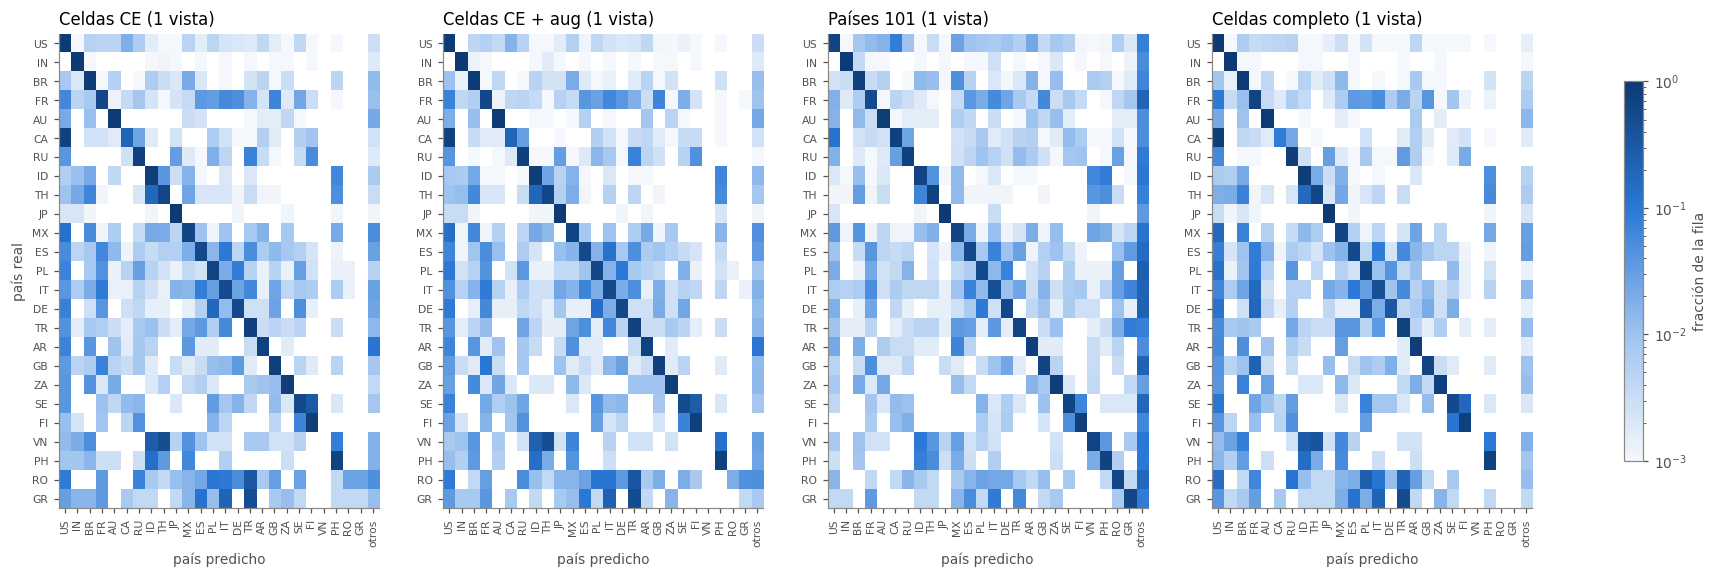

In [14]:
soporte_test = np.bincount(pais_test[primera], minlength=len(PAISES))
top = np.argsort(-soporte_test)[:25]
fig, ejes = plt.subplots(1, len(modelos), figsize=(5.4 * len(modelos), 5.6))
ejes = np.atleast_1d(ejes)
for eje, nombre in zip(ejes, modelos):
    cm = cm_pais[(nombre, "1 vista")]
    sub = np.column_stack([cm[np.ix_(top, top)], cm[top].sum(1) - cm[np.ix_(top, top)].sum(1)])
    sub = sub / np.maximum(sub.sum(1, keepdims=True), 1)
    im = eje.imshow(np.where(sub > 0, sub, np.nan), cmap=SECUENCIAL, norm=LogNorm(1e-3, 1), aspect="auto")
    etiquetas = [PAISES[i] for i in top]
    eje.set_xticks(range(len(top) + 1), etiquetas + ["otros"], rotation=90, fontsize=7)
    eje.set_yticks(range(len(top)), etiquetas, fontsize=7)
    eje.set_title(f"{NOMBRES[nombre]} (1 vista)", loc="left")
    eje.set_xlabel("país predicho")
    eje.grid(False)
ejes[0].set_ylabel("país real")
fig.colorbar(im, ax=ejes, shrink=0.8, label="fracción de la fila")
plt.show()

Los pares de países más confundidos por cada modelo (1 vista). `% del real` es la fracción de las imágenes de ese país que se fueron al otro.

In [15]:
filas = []
for nombre in modelos:
    cm = cm_pais[(nombre, "1 vista")].copy()
    soporte = cm.sum(1)
    np.fill_diagonal(cm, 0)
    for i, j in zip(*np.unravel_index(np.argsort(-cm, axis=None)[:10], cm.shape)):
        filas.append({"modelo": NOMBRES[nombre], "real": PAISES[i], "predicho": PAISES[j],
                      "imágenes": int(cm[i, j]), "% del real": cm[i, j] / soporte[i]})
pares = pd.DataFrame(filas)
pd.concat({m: g.drop(columns="modelo").reset_index(drop=True) for m, g in pares.groupby("modelo", sort=False)},
          axis=1).style.format({(m, "% del real"): "{:.1%}" for m in pares.modelo.unique()})

### 7.3 Continentes

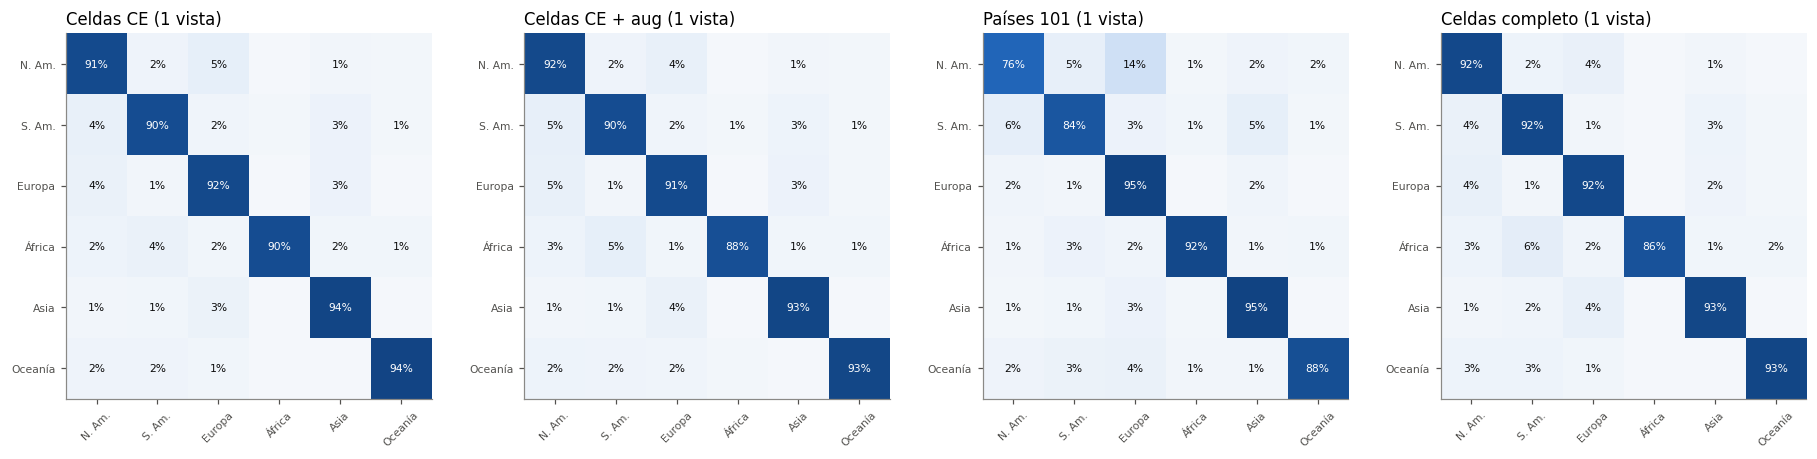

In [16]:
fig, ejes = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 4))
ejes = np.atleast_1d(ejes)
abrev = ["N. Am.", "S. Am.", "Europa", "África", "Asia", "Oceanía"]
for eje, nombre in zip(ejes, modelos):
    cm = cm_cont[(nombre, "1 vista")]
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    eje.imshow(cmn, cmap=SECUENCIAL, vmin=0, vmax=1)
    for i in range(len(CONTINENTES)):
        for j in range(len(CONTINENTES)):
            if cmn[i, j] >= 0.005:
                eje.text(j, i, f"{cmn[i, j]:.0%}", ha="center", va="center", fontsize=7,
                         color="white" if cmn[i, j] > 0.5 else "#0b0b0b")
    eje.set_xticks(range(6), abrev, rotation=45, fontsize=7)
    eje.set_yticks(range(6), abrev, fontsize=7)
    eje.set_title(f"{NOMBRES[nombre]} (1 vista)", loc="left")
    eje.grid(False)
plt.tight_layout()
plt.show()

## 8. Por país: F1 y mapas

F1 por país contra la cantidad de imágenes en test, comparando la referencia de celdas con el clasificador de
países.

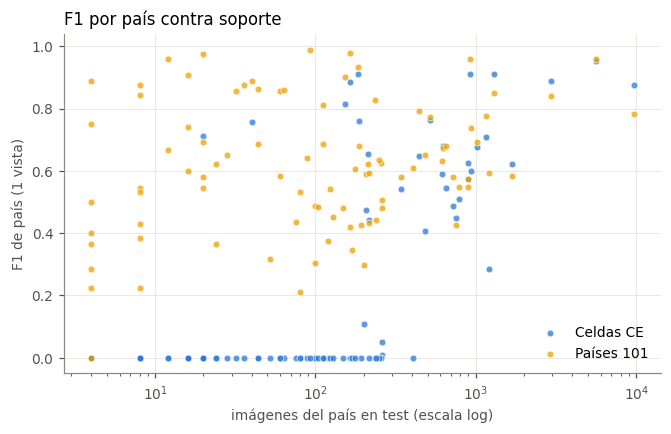

In [17]:
paises_modelos = [n for n in modelos if modelos[n]["tarea"] == "paises"]
comparar = [REFERENCIA] + paises_modelos[:1]
fig, eje = plt.subplots(figsize=(7, 4))
for nombre in comparar:
    pc = por_clase_pais[(nombre, "1 vista")]
    v = pc.soporte > 0
    eje.scatter(pc.soporte[v], pc.f1[v], s=20, color=COLORES[nombre], alpha=0.75, label=NOMBRES[nombre],
                edgecolor="white", linewidth=0.6)
eje.set_xscale("log")
eje.set_xlabel("imágenes del país en test (escala log)")
eje.set_ylabel("F1 de país (1 vista)")
eje.set_title("F1 por país contra soporte", loc="left")
eje.legend()
plt.show()

Mapas por país (1 vista): recall de país (la fracción de imágenes del país con el país acertado) y mediana
del error en km. A la derecha, la diferencia del clasificador de países contra la referencia de celdas. Los
países sin imágenes en test quedan en gris claro.

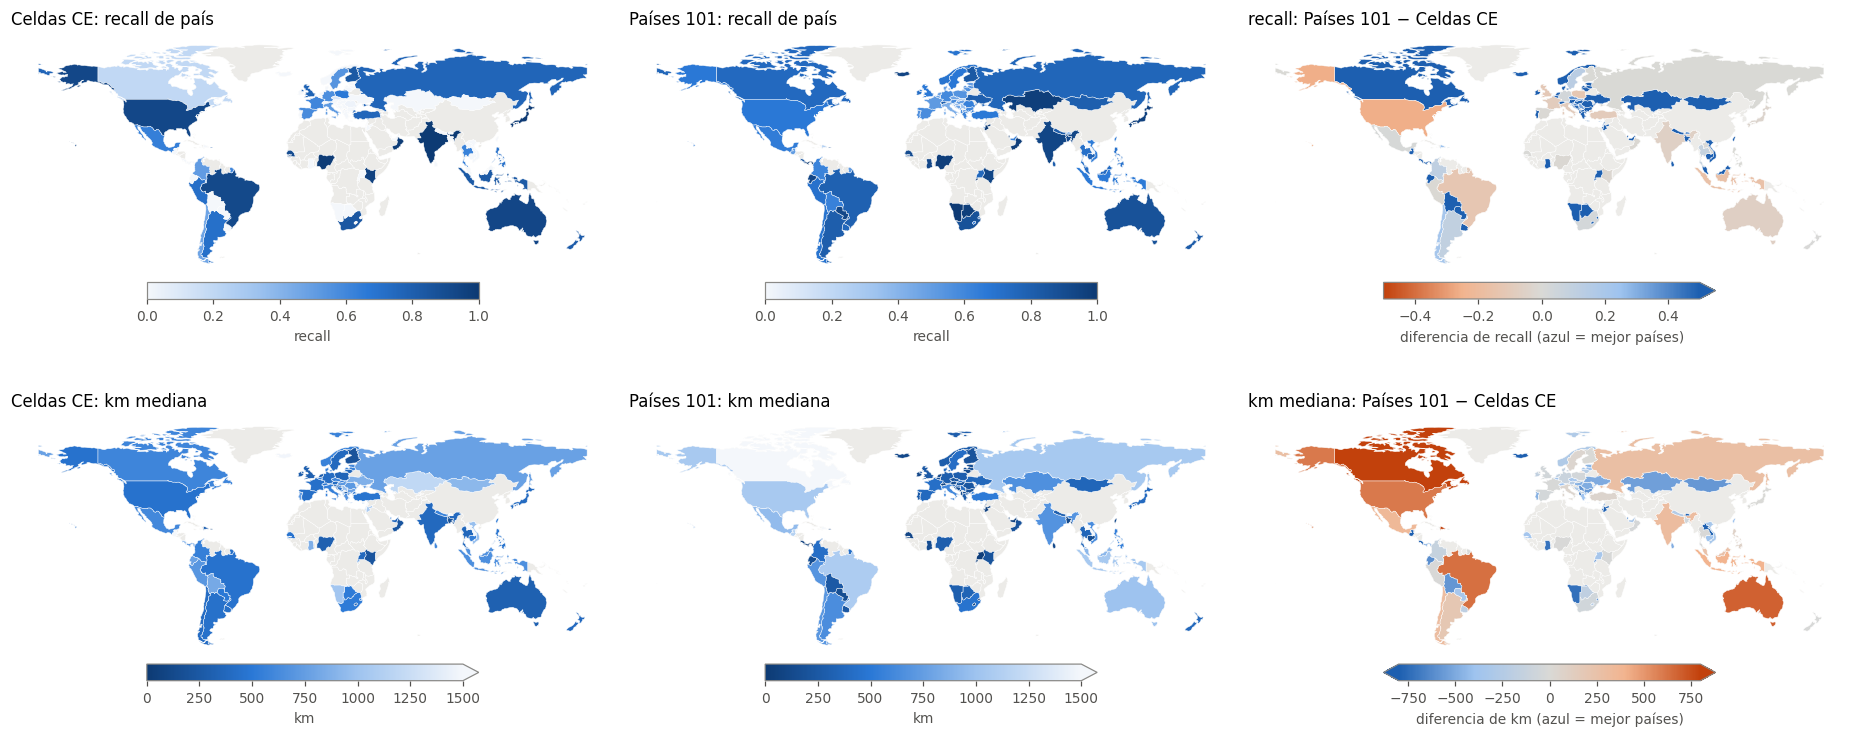

In [18]:
def por_pais_mapa(nombre, modo="1 vista"):
    r = pred[(nombre, modo)]
    df = pd.DataFrame({"pais": np.array(PAISES)[r["y_pais"]], "acierto": r["pred_pais"] == r["y_pais"], "km": r["km"]})
    return df.groupby("pais").agg(recall=("acierto", "mean"), km_mediana=("km", "median"), n=("km", "size"))


def dibujar(eje, valores, titulo, cmap, vmin, vmax, etiqueta):
    m = MUNDO[MUNDO.CONTINENT != "Antarctica"].merge(valores.rename("v"), left_on="ISO_A2_EH", right_index=True,
                                                     how="left")
    m.plot(ax=eje, color="#ecebe8", edgecolor="white", linewidth=0.3)
    m.dropna(subset=["v"]).plot(ax=eje, column="v", cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="white",
                                linewidth=0.3, legend=True,
                                legend_kwds={"shrink": 0.55, "label": etiqueta, "orientation": "horizontal",
                                             "pad": 0.02})
    eje.set_title(titulo, loc="left")
    eje.set_axis_off()


ref_pp = por_pais_mapa(REFERENCIA)
fig, ejes = plt.subplots(2, 3 if paises_modelos else 1, figsize=(17 if paises_modelos else 7, 7.5))
ejes = np.atleast_2d(ejes).reshape(2, -1)
dibujar(ejes[0, 0], ref_pp.recall, f"{NOMBRES[REFERENCIA]}: recall de país", SECUENCIAL, 0, 1, "recall")
dibujar(ejes[1, 0], ref_pp.km_mediana, f"{NOMBRES[REFERENCIA]}: km mediana", SECUENCIAL.reversed(), 0, 1500, "km")
if paises_modelos:
    pais_pp = por_pais_mapa(paises_modelos[0])
    n0 = NOMBRES[paises_modelos[0]]
    dibujar(ejes[0, 1], pais_pp.recall, f"{n0}: recall de país", SECUENCIAL, 0, 1, "recall")
    dibujar(ejes[1, 1], pais_pp.km_mediana, f"{n0}: km mediana", SECUENCIAL.reversed(), 0, 1500, "km")
    dibujar(ejes[0, 2], pais_pp.recall - ref_pp.recall, f"recall: {n0} − {NOMBRES[REFERENCIA]}",
            DIVERGENTE, -0.5, 0.5, "diferencia de recall (azul = mejor países)")
    dibujar(ejes[1, 2], pais_pp.km_mediana - ref_pp.km_mediana, f"km mediana: {n0} − {NOMBRES[REFERENCIA]}",
            DIVERGENTE.reversed(), -800, 800, "diferencia de km (azul = mejor países)")
plt.tight_layout()
plt.show()

## 9. Calibración

Diagrama de confiabilidad de la tarea propia (1 vista): confianza media contra acierto real, en 15 bins. Un modelo
bien calibrado queda sobre la diagonal. El ECE está en la tabla de la sección 3.

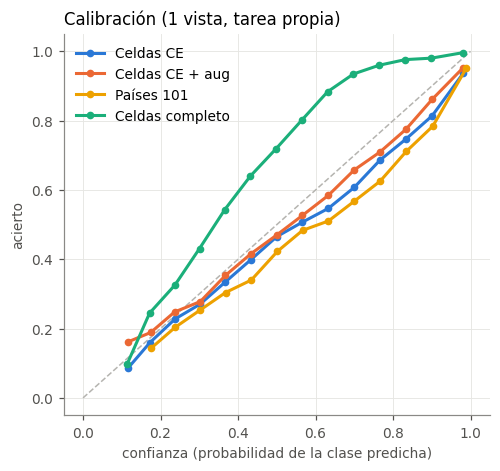

In [19]:
fig, eje = plt.subplots(figsize=(5, 4.5))
eje.plot([0, 1], [0, 1], color="#b5b4b0", lw=1, ls="--")
for nombre in modelos:
    r = pred[(nombre, "1 vista")]
    conf, ac = r["p"].max(1), r["pred"] == r["y"]
    b = np.clip((conf * 15).astype(int), 0, 14)
    x = [conf[b == i].mean() for i in range(15) if (b == i).sum() >= 30]
    y = [ac[b == i].mean() for i in range(15) if (b == i).sum() >= 30]
    eje.plot(x, y, color=COLORES[nombre], lw=2, marker="o", ms=4, label=NOMBRES[nombre])
eje.set_xlabel("confianza (probabilidad de la clase predicha)")
eje.set_ylabel("acierto")
eje.set_title("Calibración (1 vista, tarea propia)", loc="left")
eje.legend()
plt.show()

## 10. Conclusiones

Los números son de la corrida de este notebook sobre test. «Significativo» quiere decir que el IC 95% del
bootstrap pareado no contiene el 0.

1. **Test confirma lo que se vio en val: no hubo sobreajuste a la validación.** Celdas CE da 60.4% de top-1 y
   449 km de mediana en test (1 vista), contra 60.4% y 446 km en val. Las demás corridas se mueven igual de poco.

2. **Para GeoGuessr, el mejor modelo es Celdas CE combinando las 4 vistas:** 3664 puntos medios por ronda,
   381 km de mediana, 83% de las predicciones a menos de 750 km y 98% a menos de 2500 km.

3. **El clasificador de países pierde por mucho en distancia.** Saca 446 puntos menos con 1 vista y 501 con 4
   vistas (significativo), y su error medio es entre 400 y 530 km mayor. El motivo es la discretización: aun
   eligiendo siempre el país correcto, predecir el medoide deja una mediana de 439 km (el oráculo). Con celdas
   ese piso es de 321 km. En los mapas, la desventaja se concentra en los países grandes: Canadá, EE. UU.,
   Brasil, Australia y Rusia.

4. **Acertar el país:**
   - **Con 1 vista, casi empatan:** 72.4% Países 101 contra 71.5% Celdas CE (+0.9 pts, significativo pero
     chico), aunque el modelo de celdas nunca se entrenó para predecir países.
   - **Con 4 vistas, el de países saca 8 pts de ventaja** (86.4% contra 78.3%).
   - **En balanced accuracy y F1 macro de país, el de países es muy superior** (0.67 contra 0.25 con 1 vista).
     70 celdas no pueden representar países chicos: sus imágenes caen en celdas dominadas por un vecino grande.
     El caso más claro es Canadá: Celdas CE manda el 73% de sus imágenes a EE. UU. y Celdas completo, el 86%.
     También pasan Irlanda → Reino Unido, Bangladesh → India y Malasia → Indonesia.

5. **Continente: con 1 vista, el de celdas es mejor** (91.7% contra 87.9%). El de países manda el 14% de las
   imágenes de Norteamérica a países europeos. Con 4 vistas empatan (~97%).

6. **Las mejoras de generalización no mejoraron el modelo:**
   - **Augmentation** no cambia nada medible con 1 vista y pierde 20 puntos con 4 vistas.
   - **Celdas completo** (focal haversine + SAM + snapshots) empata con 1 vista y es significativamente peor con
     4 vistas: −61 puntos y −1.7 pts de país.
   - Además, Celdas completo está muy **subconfiado** (ECE 0.16 contra 0.06; queda arriba de la diagonal en la
     curva de calibración). La loss focal empuja las probabilidades hacia abajo, y eso le resta al promedio de
     las 4 vistas.

7. **Combinar las 4 vistas es la mejora más grande de todo el trabajo:** en Celdas CE suma +13 pts de top-1 de
   celda y +392 puntos GeoGuessr. Es más que cualquier diferencia entre recetas de entrenamiento.

8. **Los errores del modelo de celdas son mayormente locales:**
   - El 56% de los errores (73% con 4 vistas) cae en una de las 3 celdas vecinas.
   - Las celdas con más imágenes rinden algo peor (Spearman F1 ~ tamaño ≈ −0.27): son las zonas densas, con
     muchas celdas chicas y parecidas entre sí.
   - La mediana de 449 km ya está cerca del piso de 321 km de las 70 celdas. Para bajar mucho más hace falta
     una grilla más fina o refinar la coordenada dentro de la celda, no solo un mejor clasificador.